# Preprocesamiento del dataset CK+ (ckextended.csv)

Este notebook prepara las imágenes de CK+ para la extracción de keypoints con Face Mesh y el cálculo de las proporciones áureas.

**Clases que se usan:** neutral, enojado, feliz, triste y sorprendido. Se descartan asco, miedo y desprecio.

**Qué hace, paso a paso**
1. Carga el CSV de Kaggle y comprueba qué código numérico corresponde a cada emoción.
2. Lee `clasificacion_imagenes_ck.xlsx` y agrupa las imágenes por **sujeto** (cada fila une un neutro con las emociones de la misma persona).
3. Quita los **neutros repetidos**: CK+ trae un frame neutro por cada secuencia, así que la misma persona aparece hasta 12 veces como "neutral". Se deja **un solo neutro por sujeto** (el más representativo).
4. Preprocesa cada imagen: la escala de 48×48 a 192×192 y le agrega un margen del 25 %.
5. Control de calidad con Face Mesh: verifica que se detecte el rostro y guarda los 478 landmarks para el siguiente paso.
6. Divide los datos en folds **por sujeto**, para que la misma persona no quede en entrenamiento y en prueba a la vez.

Las salidas quedan en `ck_dataset/preprocesado/`, que ya está en el `.gitignore`.

In [2]:
%pip install scikit-learn

Note: you may need to restart the kernel to use updated packages.


In [3]:
%pip install kagglehub

  Using cached kagglehub-1.0.2-py3-none-any.whl.metadata (40 kB)
  Using cached kagglesdk-0.1.37-py3-none-any.whl.metadata (13 kB)
  Using cached pyyaml-6.0.3-cp312-cp312-win_amd64.whl.metadata (2.4 kB)
Using cached kagglehub-1.0.2-py3-none-any.whl (70 kB)
Using cached kagglesdk-0.1.37-py3-none-any.whl (262 kB)
Using cached pyyaml-6.0.3-cp312-cp312-win_amd64.whl (154 kB)

   ---------- ----------------------------- 1/4 [pyyaml]
   -------------------- ------------------- 2/4 [kagglesdk]
   -------------------- ------------------- 2/4 [kagglesdk]
   -------------------- ------------------- 2/4 [kagglesdk]
   -------------------- ------------------- 2/4 [kagglesdk]
   ------------------------------ --------- 3/4 [kagglehub]
   ---------------------------------------- 4/4 [kagglehub]

Note: you may need to restart the kernel to use updated packages.


In [4]:
%pip install openpyxl

  Using cached openpyxl-3.1.5-py2.py3-none-any.whl.metadata (2.5 kB)
  Using cached et_xmlfile-2.0.0-py3-none-any.whl.metadata (2.7 kB)
Using cached openpyxl-3.1.5-py2.py3-none-any.whl (250 kB)
Using cached et_xmlfile-2.0.0-py3-none-any.whl (18 kB)

   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   -------------------- ------------------- 1/2 [openpyxl]
   ---------------------------------------- 2/2 [openpyxl]

Note: you may need to restart the kernel to use updated packages.


In [5]:
%pip install opencv-python

  Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
Using cached opencv_python-5.0.0.93-cp37-abi3-win_amd64.whl (44.0 MB)
Note: you may need to restart the kernel to use updated packages.


In [1]:
%pip install mediapipe
import mediapipe as mp
print(mp.__version__)


  Using cached mediapipe-1.1.1-py3-none-win_amd64.whl.metadata (10 kB)
  Using cached sounddevice-0.5.6-py3-none-win_amd64.whl.metadata (1.4 kB)
  Using cached opencv_contrib_python-5.0.0.93-cp37-abi3-win_amd64.whl.metadata (20 kB)
  Using cached cffi-2.1.1-cp312-cp312-win_amd64.whl.metadata (2.6 kB)
Using cached mediapipe-1.1.1-py3-none-win_amd64.whl (22.8 MB)
Using cached sounddevice-0.5.6-py3-none-win_amd64.whl (1.0 MB)
Using cached cffi-2.1.1-cp312-cp312-win_amd64.whl (185 kB)
Using cached opencv_contrib_python-5.0.0.93-cp37-abi3-win_amd64.whl (53.8 MB)

   ---------------------------------------- 0/4 [opencv-contrib-python]
   ---------------------------------------- 0/4 [opencv-contrib-python]
   ---------------------------------------- 0/4 [opencv-contrib-python]
   ---------------------------------------- 0/4 [opencv-contrib-python]
   ---------- ----------------------------- 1/4 [cffi]
   ------------------------------ --------- 3/4 [mediapipe]
   -----------------------------

## 1. Configuración

In [2]:
from pathlib import Path
from collections import Counter, defaultdict
import shutil

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import mediapipe as mp
from sklearn.model_selection import StratifiedGroupKFold

# ---------------- Rutas ----------------
EXCEL_PATH = Path("clasificacion_imagenes_ck.xlsx")
OUTPUT_DIR = Path("ck_dataset") / "preprocesado"

# Ruta al CSV. kagglehub usa la caché si ya se descargó antes.
CSV_PATH = None          # p. ej. Path(r"C:\Users\...\ckextended.csv") para fijarla a mano
if CSV_PATH is None:
    import kagglehub
    CSV_PATH = Path(kagglehub.dataset_download("davilsena/ckdataset")) / "ckextended.csv"
print("CSV:", CSV_PATH)

# ---------------- Clases ----------------
# Nombre de la columna del Excel -> etiqueta final (en español)
EXCEL_COLS = {"Neutral": "neutral", "Anger": "enojado", "Happiness": "feliz",
              "Sadness": "triste", "Surprise": "sorprendido"}
CLASES = ["neutral", "enojado", "feliz", "triste", "sorprendido"]
CLASE_A_ID = {c: i for i, c in enumerate(CLASES)}

# ---------------- Preprocesamiento de imagen ----------------
IMG_SIZE_ORIG = 48     # el CSV trae imágenes de 48x48
IMG_SIZE = 192         # tamaño tras escalar (entrada típica del modelo de landmarks)
PAD_FRAC = 0.25        # margen alrededor del rostro (fracción del lado)
USAR_CLAHE = False     # ver nota en la sección 6

N_FOLDS = 5
SEED = 42

c:\Users\andre\anaconda3\envs\diplomado\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


CSV: C:\Users\andre\.cache\kagglehub\datasets\davilsena\ckdataset\versions\2\ckextended.csv


## 2. Cargar el CSV y verificar los códigos de emoción

In [3]:
df = pd.read_csv(CSV_PATH)
df["img_id"] = "image_" + df.index.astype(str)   # mismo nombre que usa el Excel
print(df.shape)
print(df["emotion"].value_counts().sort_index())

def pixels_a_array(pix_str, size=IMG_SIZE_ORIG):
    return np.array(pix_str.split(), dtype=np.uint8).reshape(size, size)

imgs48 = {row.img_id: pixels_a_array(row.pixels) for row in df.itertuples()}
codigo_csv = dict(zip(df["img_id"], df["emotion"]))

(920, 4)
emotion
0     45
1     59
2     25
3     69
4     28
5     83
6    593
7     18
Name: count, dtype: int64


## 3. Leer el Excel y agrupar por sujeto

Cada fila del Excel tiene un neutro y las imágenes de enojo, felicidad, tristeza y sorpresa **de la misma persona**. Para encontrar a cada sujeto se unen todas las imágenes que aparecen juntas en alguna fila (*union-find*): si el neutro A aparece con la feliz X, y el neutro B también aparece con X, entonces A, B y X son de la misma persona.

Hay que considerar dos casos:
- **Filas incompletas** (por ejemplo, a una fila le falta la tristeza): no es un problema, porque las demás filas del sujeto la completan.
- **Filas conflictivas**: una fila que une a dos personas distintas. Se detectan porque el grupo resultante tendría dos imágenes de la misma emoción. Esa fila se descarta y se reporta para corregirla en el Excel.

In [4]:
raw = pd.read_excel(EXCEL_PATH, header=None)

# Buscar la fila de encabezados ("Neutral", "Anger (0)", ...)
hdr_row = next(i for i in range(10) if raw.iloc[i].fillna("").astype(str).str.strip().eq("Neutral").any())
hdr = raw.iloc[hdr_row].fillna("").astype(str).str.strip()
col_idx = {}
for nombre in EXCEL_COLS:
    col_idx[nombre] = next(j for j, h in enumerate(hdr) if h.startswith(nombre))

tabla = raw.iloc[hdr_row + 1:, list(col_idx.values())].copy()
tabla.columns = [EXCEL_COLS[n] for n in col_idx]
tabla = tabla[tabla["neutral"].fillna("").astype(str).str.startswith("image_")].reset_index(drop=True)
tabla = tabla.astype(object).apply(lambda col: col.map(lambda v: v.strip() if isinstance(v, str) and v.strip() else None))
print("Filas de la tabla:", len(tabla))

# --- Verificar que cada columna del Excel corresponde a un único código del CSV ---
codigo_de_clase = {}
for c in CLASES:
    codigos = Counter(codigo_csv[i] for i in tabla[c].dropna())
    assert len(codigos) == 1, f"La columna {c} mezcla códigos del CSV: {codigos}"
    codigo_de_clase[c] = next(iter(codigos))
print("Código del CSV por clase:", codigo_de_clase)
clase_de_codigo = {v: k for k, v in codigo_de_clase.items()}
EMOCIONES = [c for c in CLASES if c != "neutral"]

Filas de la tabla: 593
Código del CSV por clase: {'neutral': 6, 'enojado': 0, 'feliz': 3, 'triste': 4, 'sorprendido': 5}


In [26]:
class UnionFind:
    def __init__(self):
        self.p = {}
    def find(self, x):
        self.p.setdefault(x, x)
        while self.p[x] != x:
            self.p[x] = self.p[self.p[x]]
            x = self.p[x]
        return x
    def union(self, a, b):
        self.p[self.find(a)] = self.find(b)

def agrupar(filas):
    uf = UnionFind()
    for r in filas.to_dict("records"):
        uf.find(r["neutral"])
        for e in EMOCIONES:
            if isinstance(r[e], str):
                uf.union(r["neutral"], r[e])
    grupos = defaultdict(set)
    for x in list(uf.p):
        grupos[uf.find(x)].add(x)
    return list(grupos.values())

def clase_img(img_id):
    return clase_de_codigo[codigo_csv[img_id]]

def tiene_conflicto(grupo):
    cnt = Counter(clase_img(i) for i in grupo if clase_img(i) != "neutral")
    return any(v > 1 for v in cnt.values())

# --- Resolver filas conflictivas ---
filas_conflictivas = []
while True:
    grupos = agrupar(tabla)
    malos = [g for g in grupos if tiene_conflicto(g)]
    if not malos:
        break
    g = malos[0]
    candidatas = tabla[tabla["neutral"].isin(g)]
    resuelto = False
    for k, fila in candidatas.iterrows():   # probar quitando una fila a la vez
        sub = tabla.drop(index=k)
        sub_g = [x for x in agrupar(sub) if x & g]
        if not any(tiene_conflicto(x) for x in sub_g):
            filas_conflictivas.append(fila.to_dict())
            tabla = sub
            resuelto = True
            break
    if not resuelto:
        raise RuntimeError(f"No se pudo resolver el grupo conflictivo: {sorted(g)}")

print("Filas conflictivas descartadas (revisar en el Excel):")
display(pd.DataFrame(filas_conflictivas))

Filas conflictivas descartadas (revisar en el Excel):


,neutral,enojado,feliz,triste,sorprendido
0,image_17,None,image_640,None,image_897


In [27]:
# Asignar un id de sujeto a cada imagen
grupos = sorted(agrupar(tabla), key=lambda g: min(int(i.split("_")[1]) for i in g))
sujeto_de = {}
sujetos_con_emocion = 0
for g in grupos:
    if all(clase_img(i) == "neutral" for i in g):
        continue                      # neutro sin ninguna emoción enlazada
    sid = f"S{sujetos_con_emocion:03d}"
    sujetos_con_emocion += 1
    for i in g:
        sujeto_de[i] = sid

# Neutros que no quedaron enlazados a ninguna emoción
neutros_tabla = set(tabla["neutral"])
neutros_sin_sujeto = sorted({i for i in neutros_tabla if i not in sujeto_de},
                            key=lambda s: int(s.split("_")[1]))
neutros_conflictivos = [f["neutral"] for f in filas_conflictivas]

print("Sujetos identificados:", sujetos_con_emocion)
print("Neutros sin emoción enlazada:", len(neutros_sin_sujeto))
for e in EMOCIONES:
    total = (df["emotion"] == codigo_de_clase[e]).sum()
    enlazadas = sum(1 for i, s in sujeto_de.items() if clase_img(i) == e)
    print(f"  {e:12s} imágenes en CSV: {total:3d} | con sujeto asignado: {enlazadas:3d}")

Sujetos identificados: 103
Neutros sin emoción enlazada: 53
  enojado      imágenes en CSV:  45 | con sujeto asignado:  45
  feliz        imágenes en CSV:  69 | con sujeto asignado:  69
  triste       imágenes en CSV:  28 | con sujeto asignado:  28
  sorprendido  imágenes en CSV:  83 | con sujeto asignado:  83


## 4. Validar la agrupación con similitud de píxeles

Comprobación independiente del Excel: si la agrupación es correcta, el neutro más parecido (en píxeles) a cada neutro debería pertenecer al **mismo sujeto**. Un porcentaje alto confirma que el Excel está bien. Los casos que fallan se muestran para revisarlos a ojo.

Neutros cuyo vecino más cercano es del mismo sujeto: 99.8% (536/537)


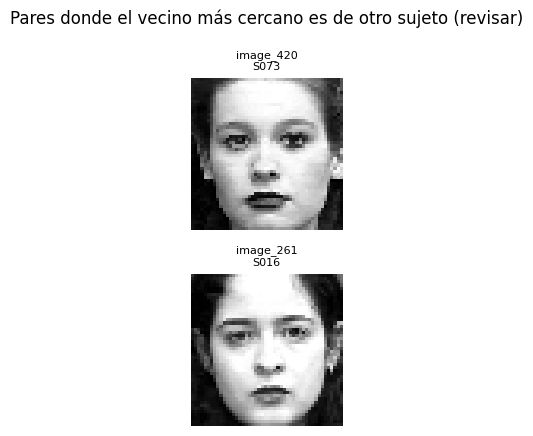

In [28]:
def vec_norm(img):
    v = img.astype(np.float32).ravel()
    return (v - v.mean()) / (v.std() + 1e-6)

def dist_matriz(V):
    # Distancia RMS entre vectores normalizados (media 0, desv. 1): ||a-b||^2/d = 2 - 2*a.b/d
    return np.sqrt(np.maximum(2 - 2 * (V @ V.T) / V.shape[1], 0))

neutros_con_sujeto = [i for i in sujeto_de if clase_img(i) == "neutral"]
X = np.stack([vec_norm(imgs48[i]) for i in neutros_con_sujeto])
D = dist_matriz(X)
np.fill_diagonal(D, np.inf)
vecino = D.argmin(1)
sid = np.array([sujeto_de[i] for i in neutros_con_sujeto])
cuenta = Counter(sid)
evaluables = np.array([cuenta[s] > 1 for s in sid])   # solo sujetos con >1 neutro
acierto = (sid[vecino] == sid)[evaluables]
print(f"Neutros cuyo vecino más cercano es del mismo sujeto: {acierto.mean():.1%} "
      f"({acierto.sum()}/{evaluables.sum()})")

fallos = [(neutros_con_sujeto[k], neutros_con_sujeto[vecino[k]])
          for k in np.where(evaluables & (sid[vecino] != sid))[0]]
if fallos:
    n = min(len(fallos), 8)
    fig, ax = plt.subplots(2, n, figsize=(2 * n, 4.4), squeeze=False)
    for j, (a, b) in enumerate(fallos[:n]):
        ax[0, j].imshow(imgs48[a], cmap="gray"); ax[0, j].set_title(f"{a}\n{sujeto_de[a]}", fontsize=8)
        ax[1, j].imshow(imgs48[b], cmap="gray"); ax[1, j].set_title(f"{b}\n{sujeto_de[b]}", fontsize=8)
        ax[0, j].axis("off"); ax[1, j].axis("off")
    fig.suptitle("Pares donde el vecino más cercano es de otro sujeto (revisar)")
    plt.tight_layout(); plt.show()

## 5. Quitar neutros repetidos y armar el conjunto final

- **Neutral:** se deja **un neutro por sujeto**, el *medoide*, que es el neutro con menor distancia media a los demás neutros de esa persona (el más típico). Los demás se guardan en `neutros_por_sujeto.csv` por si después quieres promediar los landmarks del rostro neutro para calcular las diferencias Δ (pico − neutro).
- **Emociones:** cada imagen de emoción ya es única (una por secuencia), así que se conservan todas.
- **Se excluyen:** los neutros sin emoción enlazada (no sirven para Δ y no se puede saber de qué sujeto son, lo que arriesga fuga de datos entre folds), los neutros de filas conflictivas y las clases asco, miedo y desprecio.

In [29]:
filas = []
excluidas = []
neutros_por_sujeto = defaultdict(list)
for i, s in sujeto_de.items():
    if clase_img(i) == "neutral":
        neutros_por_sujeto[s].append(i)

neutro_ref = {}
for s, lista in neutros_por_sujeto.items():
    lista = sorted(lista, key=lambda x: int(x.split("_")[1]))
    if len(lista) == 1:
        rep = lista[0]
    else:
        V = np.stack([vec_norm(imgs48[i]) for i in lista])
        d = dist_matriz(V).mean(1)
        rep = lista[int(d.argmin())]
    neutro_ref[s] = rep
    for i in lista:
        if i != rep:
            excluidas.append({"img_id": i, "motivo": f"neutro repetido de {s} (se usa {rep})"})

for i, s in sujeto_de.items():
    c = clase_img(i)
    if c == "neutral" and i != neutro_ref[s]:
        continue
    filas.append({"img_id": i, "idx_csv": int(i.split("_")[1]), "clase": c,
                  "clase_id": CLASE_A_ID[c], "sujeto": s, "neutro_ref": neutro_ref[s]})

for i in neutros_sin_sujeto:
    excluidas.append({"img_id": i, "motivo": "neutro sin emoción enlazada en el Excel"})
for i in neutros_conflictivos:
    if i not in sujeto_de:
        excluidas.append({"img_id": i, "motivo": "fila conflictiva en el Excel"})
usadas = set(codigo_de_clase.values())
for i in df.loc[~df["emotion"].isin(usadas), "img_id"]:
    excluidas.append({"img_id": i, "motivo": "clase no usada (asco/miedo/desprecio)"})

meta = pd.DataFrame(filas).sort_values("idx_csv").reset_index(drop=True)
excluidas = pd.DataFrame(excluidas)
print("Imágenes en el conjunto final:", len(meta))
print(meta["clase"].value_counts().reindex(CLASES))
print("\nExcluidas por motivo:")
print(excluidas["motivo"].str.replace(r" de S\d+.*", "", regex=True).value_counts())

Imágenes en el conjunto final: 328
clase
neutral        103
enojado         45
feliz           69
triste          28
sorprendido     83
Name: count, dtype: int64

Excluidas por motivo:
motivo
neutro repetido                            436
clase no usada (asco/miedo/desprecio)      102
neutro sin emoción enlazada en el Excel     53
fila conflictiva en el Excel                 1
Name: count, dtype: int64


## 6. Preprocesamiento de la imagen

Las imágenes del CSV son recortes de 48×48 en escala de grises. Se aplica:
1. **Escalado a 192×192** con interpolación bicúbica.
2. **Margen del 25 %** replicando el borde. El detector de MediaPipe funciona mejor cuando el rostro no toca los bordes de la imagen.
3. **Conversión a RGB** al momento de pasarla a MediaPipe (se guarda en gris).

**Nota sobre CLAHE / ecualización:** se probó en recortes de 48×48 del mismo formato (FER) y **empeoró la estabilidad de los landmarks** (amplifica el ruido de la imagen pequeña). Por eso está desactivado por defecto (`USAR_CLAHE`). La normalización que sí importa para las proporciones se hace después, sobre los landmarks (escala y rotación), no sobre los píxeles.

In [30]:
_clahe = cv2.createCLAHE(clipLimit=2.0, tileGridSize=(4, 4))

def preprocesar(img48, size=IMG_SIZE, pad_frac=PAD_FRAC, usar_clahe=USAR_CLAHE):
    img = _clahe.apply(img48) if usar_clahe else img48
    img = cv2.resize(img, (size, size), interpolation=cv2.INTER_CUBIC)
    p = int(round(size * pad_frac))
    return cv2.copyMakeBorder(img, p, p, p, p, cv2.BORDER_REPLICATE)

if OUTPUT_DIR.exists():
    shutil.rmtree(OUTPUT_DIR)
for c in CLASES:
    (OUTPUT_DIR / "imagenes" / c).mkdir(parents=True, exist_ok=True)

rutas = []
for row in meta.itertuples():
    out = preprocesar(imgs48[row.img_id])
    ruta = OUTPUT_DIR / "imagenes" / row.clase / f"{row.img_id}.png"
    cv2.imwrite(str(ruta), out)
    rutas.append(ruta.as_posix())
meta["ruta"] = rutas
print("Imágenes guardadas:", len(rutas), "| tamaño final:", out.shape)

Imágenes guardadas: 328 | tamaño final: (288, 288)


## 7. Control de calidad con Face Mesh

Se corre Face Mesh sobre cada imagen preprocesada. Si no detecta el rostro con confianza 0.5, se reintenta con 0.3. Las imágenes donde no se detecta se marcan con `rostro_detectado = False`.

Los 478 landmarks (x, y en píxeles de la imagen preprocesada, z en la misma escala que x) se guardan en `landmarks.npz` para no tener que recalcularlos en el notebook de proporciones áureas.

In [31]:
# MediaPipe tiene dos APIs:
#  - Clásica  (mp.solutions.face_mesh): versiones antiguas, la que usan los otros notebooks.
#  - Tasks    (FaceLandmarker): versiones nuevas (>= 0.10.3x ya no traen mp.solutions).
# Se usa la que esté disponible. Ambas devuelven los mismos 478 landmarks.
USA_API_CLASICA = hasattr(mp, "solutions")
MODELO_TASK = Path("modelos") / "face_landmarker.task"
URL_MODELO = ("https://storage.googleapis.com/mediapipe-models/face_landmarker/"
              "face_landmarker/float16/latest/face_landmarker.task")

if not USA_API_CLASICA:
    from mediapipe.tasks.python import BaseOptions, vision
    if not MODELO_TASK.exists():
        import urllib.request
        MODELO_TASK.parent.mkdir(parents=True, exist_ok=True)
        print("Descargando modelo FaceLandmarker...")
        urllib.request.urlretrieve(URL_MODELO, MODELO_TASK)
print("MediaPipe", mp.__version__, "| API:", "clásica" if USA_API_CLASICA else "Tasks")

def crear_face_mesh(conf):
    if USA_API_CLASICA:
        return mp.solutions.face_mesh.FaceMesh(static_image_mode=True, max_num_faces=1,
                                               refine_landmarks=True, min_detection_confidence=conf)
    opciones = vision.FaceLandmarkerOptions(
        base_options=BaseOptions(model_asset_path=str(MODELO_TASK)),
        running_mode=vision.RunningMode.IMAGE, num_faces=1,
        min_face_detection_confidence=conf, min_face_presence_confidence=conf)
    return vision.FaceLandmarker.create_from_options(opciones)

def landmarks_de(face_mesh, img_gray):
    rgb = np.ascontiguousarray(cv2.cvtColor(img_gray, cv2.COLOR_GRAY2RGB))
    if USA_API_CLASICA:
        res = face_mesh.process(rgb)
        puntos = res.multi_face_landmarks[0].landmark if res.multi_face_landmarks else None
    else:
        res = face_mesh.detect(mp.Image(image_format=mp.ImageFormat.SRGB, data=rgb))
        puntos = res.face_landmarks[0] if res.face_landmarks else None
    if puntos is None:
        return None
    h, w = img_gray.shape
    return np.array([(p.x * w, p.y * h, p.z * w) for p in puntos], dtype=np.float32)

lms, detectado = {}, []
with crear_face_mesh(0.5) as fm05, crear_face_mesh(0.3) as fm03:
    for row in meta.itertuples():
        img = cv2.imread(row.ruta, cv2.IMREAD_GRAYSCALE)
        L = landmarks_de(fm05, img)
        if L is None:
            L = landmarks_de(fm03, img)
        detectado.append(L is not None)
        if L is not None:
            lms[row.img_id] = L

meta["rostro_detectado"] = detectado
print(f"Rostro detectado: {meta['rostro_detectado'].mean():.1%} ({sum(detectado)}/{len(meta)})")
print(meta.groupby("clase")["rostro_detectado"].mean().reindex(CLASES).map("{:.1%}".format))
if (~meta["rostro_detectado"]).any():
    display(meta.loc[~meta["rostro_detectado"], ["img_id", "clase", "sujeto"]])

ids_lm = sorted(lms, key=lambda s: int(s.split("_")[1]))
np.savez_compressed(OUTPUT_DIR / "landmarks.npz",
                    img_id=np.array(ids_lm), landmarks=np.stack([lms[i] for i in ids_lm]))

MediaPipe 0.10.32 | API: Tasks
Rostro detectado: 100.0% (328/328)
clase
neutral        100.0%
enojado        100.0%
feliz          100.0%
triste         100.0%
sorprendido    100.0%
Name: rostro_detectado, dtype: object


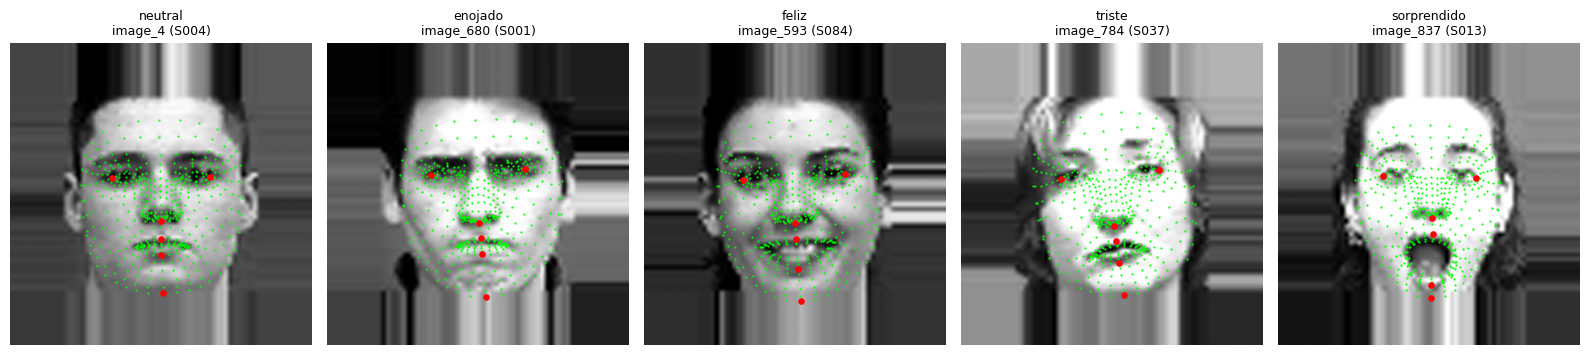

In [33]:
# Vista rápida: un ejemplo por clase con los landmarks usados en el proyecto
PUNTOS = {33: "ojo izq", 263: "ojo der", 2: "base nariz", 152: "mentón", 0: "labio sup", 17: "labio inf"}
fig, ax = plt.subplots(1, len(CLASES), figsize=(3.2 * len(CLASES), 3.6))
for k, c in enumerate(CLASES):
    fila = meta[(meta["clase"] == c) & meta["rostro_detectado"]].iloc[0]
    img = cv2.imread(fila["ruta"], cv2.IMREAD_GRAYSCALE)
    L = lms[fila["img_id"]]
    ax[k].imshow(img, cmap="gray")
    ax[k].scatter(L[:, 0], L[:, 1], s=0.3, c="lime")
    ax[k].scatter(L[list(PUNTOS), 0], L[list(PUNTOS), 1], s=14, c="red")
    ax[k].set_title(f"{c}\n{fila['img_id']} ({fila['sujeto']})", fontsize=9); ax[k].axis("off")
plt.tight_layout(); plt.show()

## 8. Guardar resultados

In [34]:
meta.to_csv(OUTPUT_DIR / "metadata.csv", index=False)
excluidas.sort_values("img_id", key=lambda s: s.str.split("_").str[1].astype(int)) \
         .to_csv(OUTPUT_DIR / "excluidas.csv", index=False)
pd.DataFrame([{"sujeto": s, "neutro_ref": neutro_ref[s], "n_neutros": len(v),
               "neutros": ";".join(sorted(v, key=lambda x: int(x.split("_")[1])))}
              for s, v in sorted(neutros_por_sujeto.items())]) \
  .to_csv(OUTPUT_DIR / "neutros_por_sujeto.csv", index=False)
pd.DataFrame(filas_conflictivas).to_csv(OUTPUT_DIR / "filas_conflictivas_excel.csv", index=False)

print("Archivos en", OUTPUT_DIR.resolve())
for p in sorted(OUTPUT_DIR.iterdir()):
    print("  ", p.name)
print("\nResumen final (con rostro detectado):")
print(meta[meta["rostro_detectado"]]["clase"].value_counts().reindex(CLASES).to_string())

Archivos en C:\Users\Lucia\phi\Phi_detection\ck_dataset\preprocesado
   excluidas.csv
   filas_conflictivas_excel.csv
   imagenes
   landmarks.npz
   metadata.csv
   neutros_por_sujeto.csv

Resumen final (con rostro detectado):
clase
neutral        103
enojado         45
feliz           69
triste          28
sorprendido     83
